# 산불 발생 및 피해 현황 분석 (1995 ~ 2025)
동국대 AI캠퍼스 · matplotlib 프로젝트 예제

- 데이터: KOSIS 산불 피해 현황
- 흐름: 문제정의 → 데이터 준비(제공) → 전국 추이 → 지역 비교 → 결론

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------
# 한글 폰트 설정 (OS 자동 감지)
# ---------------------------------------
import platform
_os = platform.system()
if _os == 'Windows':
    plt.rc('font', family='Malgun Gothic')     # 윈도우
elif _os == 'Darwin':
    plt.rc('font', family='AppleGothic')        # 맥
else:
    plt.rc('font', family='NanumGothic')        # 리눅스 / 구글 코랩
plt.rc('axes', unicode_minus=False)
plt.rc('figure', figsize=(12, 5))

## 문제 정의
- 연도별 산불 **발생 건수**와 **피해 규모**(면적·피해액·인명)는 어떻게 변해왔나?
- 산불의 주요 **원인**은?
- **2025년 대형 산불**은 어느 **지역**에서, 얼마나 크게 났나?

## 데이터 준비 (제공)
> **데이터 준비 코드는 미리 작성해 두었습니다(다단 헤더 처리는 pandas 심화 내용).**
>  아래 표(`tot`)는 **연도별로 정리된 쉬운 컬럼**이니, 우리는 **시각화에 집중**합니다.

In [2]:
# ----------------------------------------
# [제공] 원본 CSV 로드 + 정제 + 컬럼 정리
#   - 원본은 지역·항목이 겹친 다단 헤더라 아래에서 한 번에 정리합니다.
# ----------------------------------------
data_file = 'data/산불데이터/산불피해_현황_20260712202157.csv'
raw = pd.read_csv(data_file, header=[0, 1, 2])
raw = raw.set_index(('시점', '시점', '시점'))
raw.index.name = '연도'

# '-'(값 없음)→0, 천단위 콤마 제거 후 숫자형
raw = raw.apply(lambda s: pd.to_numeric(
    s.astype(str).str.replace('-', '0').str.replace(',', ''), errors='coerce')).fillna(0)

# 전국 총계만 뽑아 '쉬운 컬럼명'으로 정리 → tot
tot = raw['총계'].copy()
tot.columns = ['발생건수','입산자실화','규반소각','논밭두렁소각','쓰레기소각','담뱃불실화',
               '성묘객실화','어린이불장난','건축물화재','기타',
               '피해건수','피해면적','피해재적','피해액','인명피해','사망','부상']
tot.head()

,발생건수,입산자실화,규반소각,논밭두렁소각,쓰레기소각,담뱃불실화,성묘객실화,어린이불장난,건축물화재,기타,피해건수,피해면적,피해재적,피해액,인명피해,사망,부상
연도,,,,,,,,,,,,,,,,,
1995,630,312,0,138,0,0,34,18,0,128,630,1013.27,5452,450678,26,25,1
1996,527,248,0,73,0,0,38,30,0,138,527,5367.63,363471,13321974,26,24,2
1997,524,247,0,103,41,29,33,10,0,61,524,2329.79,40815,1628712,30,24,6
1998,265,104,0,65,24,13,16,11,0,32,265,1014.00,44092,2516219,16,15,1
1999,315,156,0,57,13,21,20,10,0,38,315,472.79,6377,665661,5,5,0


## 전국 산불 추이

#### 연도별 발생 건수

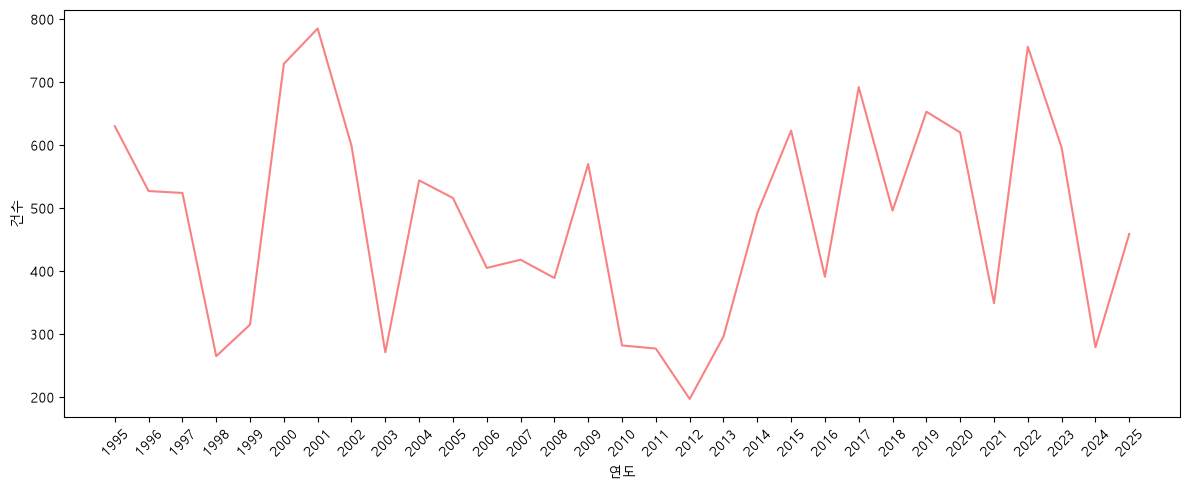

In [ ]:
# 👉 여기에 코드를 작성하세요
plt.plot(tot.index, tot['발생건수'], color="#FA8181")
plt.xlabel('연도'); plt.ylabel('건수')
plt.xticks(tot.index, rotation=45)
plt.tight_layout()
pass

#### 연도별 피해 면적 (ha) — 막대 + 추세선

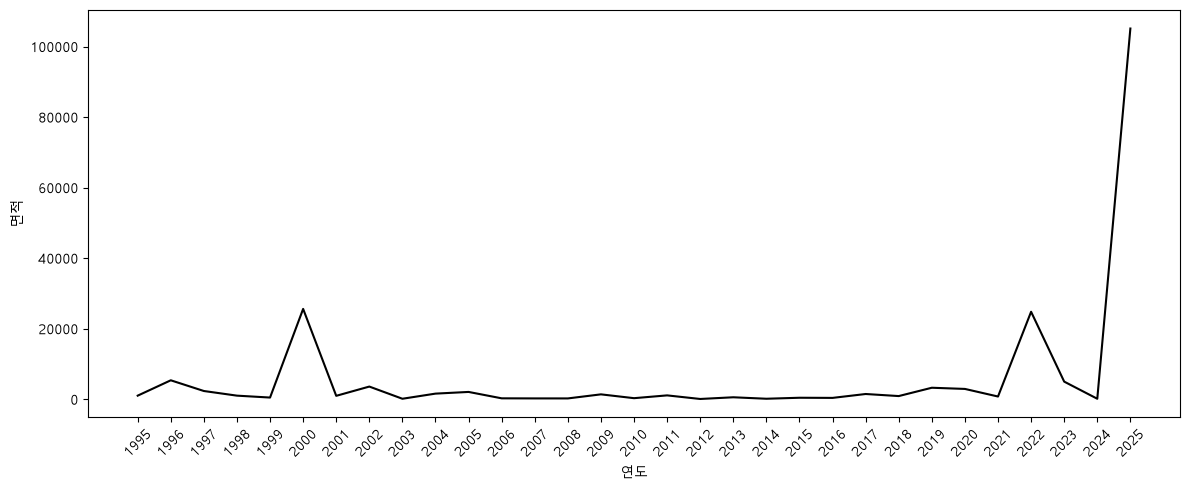

In [22]:
# 👉 여기에 코드를 작성하세요
plt.plot(tot.index, tot['피해면적'], color='#000000')
plt.xlabel('연도'); plt.ylabel('면적')
plt.xticks(tot.index, rotation=45)
plt.tight_layout()
pass

> 2025년이 너무 커서 다른 해가 안 보입니다. y축을 **당겨서** 이전 추세를 확대해 봅니다.

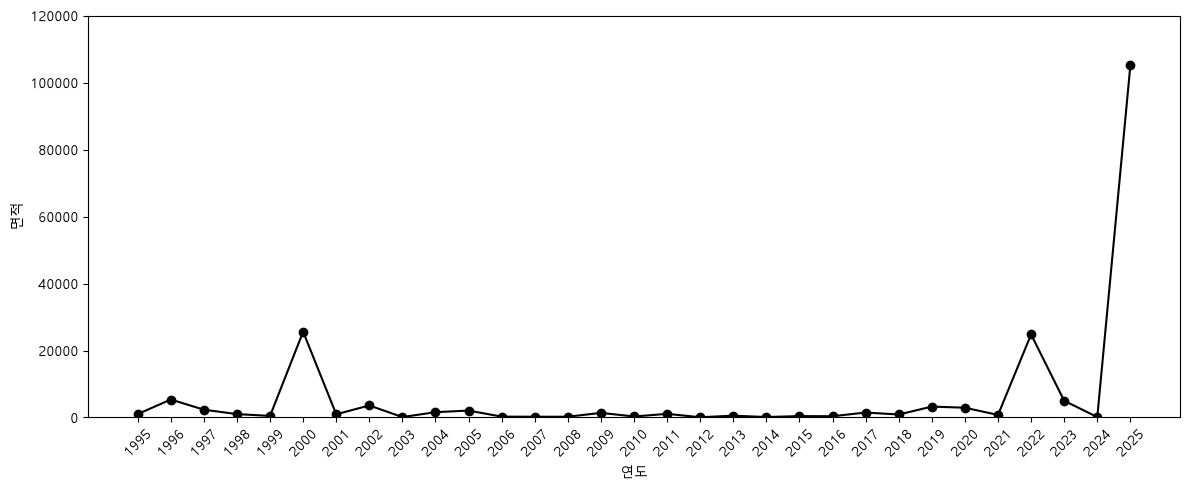

In [31]:
# 👉 여기에 코드를 작성하세요

plt.plot(tot.index, tot['피해면적'], color='#000000', marker='o')
plt.xlabel('연도'); plt.ylabel('면적')
plt.xticks(tot.index, rotation=45)
plt.ylim(0,120000)
plt.tight_layout()
pass

#### 연도별 인명 피해 (사망 · 부상)

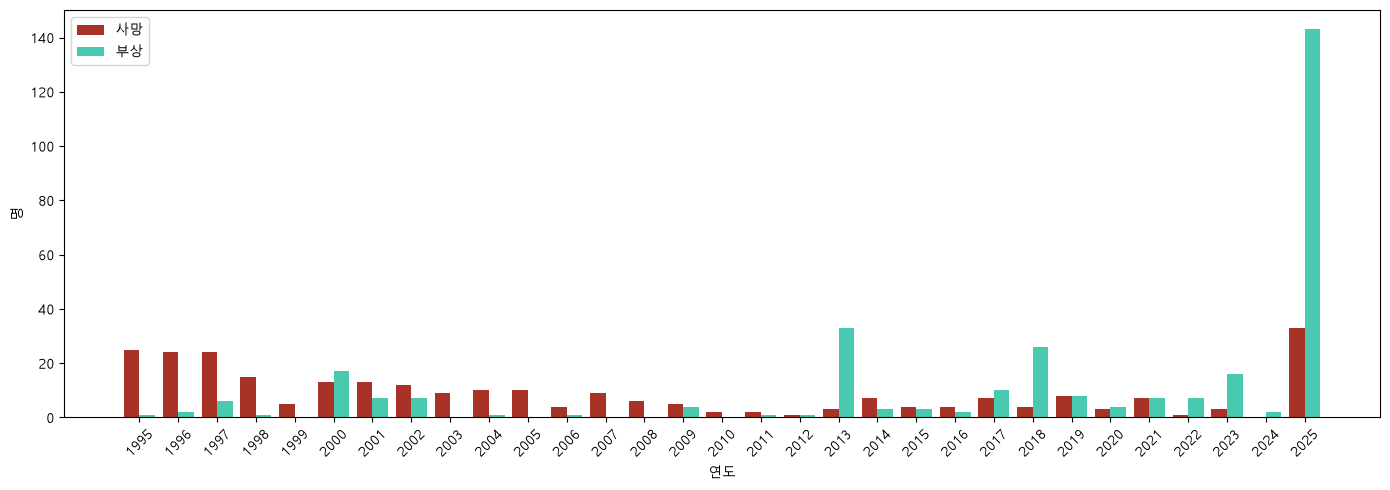

In [35]:
# 👉 여기에 코드를 작성하세요
x = tot.index

plt.figure(figsize=(14,5))
plt.bar(x - 0.2, tot['사망'], width=0.4, label='사망', color='#A93226')
plt.bar(x + 0.2, tot['부상'], width=0.4, label='부상', color='#48C9B0')
plt.xlabel('연도'); plt.ylabel('명')
plt.xticks(x, rotation=45)
plt.legend()
plt.tight_layout()
pass


## 산불 원인
원인별 발생 건수로 주요 원인과 최근 추세를 본다.

In [ ]:
# 👉 여기에 코드를 작성하세요



#### 원인별 평균 비중 (파이)

In [ ]:
# 👉 여기에 코드를 작성하세요


#### 최근 5년 원인 구성 (누적 막대)

In [ ]:
# 👉 여기에 코드를 작성하세요


## 지역별 피해 비교 — 2025년
새 데이터에는 시·도별 피해가 들어 있다. 2025년 피해 면적을 지역별로 비교한다.

In [ ]:
# [제공] 2025년 시·도별 피해 면적(ha)을 뽑아 정렬
sido = ['서울특별시','부산광역시','대구광역시','인천광역시','광주광역시','대전광역시',
        '울산광역시','세종자치시','경기도','강원특별자치도','충청북도','충청남도',
        '전북특별자치도','전라남도','경상북도','경상남도','제주도']
area_2025 = pd.Series({r: raw[(r, '산불피해', '면적 (ha)')].loc[2025] for r in sido})
area_2025 = area_2025.sort_values(ascending=False)
area_2025.round(0)

In [ ]:
# 최다 지역(경상북도)만 강조색으로

# 👉 여기에 코드를 작성하세요


In [ ]:
# 👉 여기에 코드를 작성하세요


## 종합 대시보드 (2×2 서브플롯)
지금까지 그린 핵심 그래프 4개를 **한 그림에** 모아 요약한다. (`plt.subplots` 활용)

In [ ]:
# 👉 여기에 코드를 작성하세요


## 결론
- 산불 **발생 건수**는 해마다 등락하지만 뚜렷한 증가 추세는 아니다.
- 반면 **피해 규모**는 대형 산불이 난 해에 폭발적으로 커진다.
- **2025년은 전국 피해 면적의 약 95%가 경상북도 한 곳**에서 발생했다(의성·안동 산불). 단일 대형 산불이 그해 전체를 좌우.
- 원인은 오랫동안 **입산자 실화**가 최다 → 예방 정책의 핵심 대상.